In [ ]:
# link https://clck.su/XYGEF
# link GasDynamic https://clck.su/ILpMg

# Полностью консервативная схема газовой динамики

**По А. А. Самарскому и Ю. П. Попову, гл. II, § 3, формулы (3.16)–(3.20), стр. 116–120.**

Задача: реализовать МКР в лагранжевой массовой координате, неявную схему с $\alpha=1/2$, нелинейный метод Ньютона и скалярную прогонку. Начнём с гладкого начального возмущения давления, чтобы проконтролировать законы сохранения до задач с ударными волнами.

## Шаг 1. Математическая постановка

На $0<s<1$ решаем

$$
\begin{aligned}
u_t&=-p_s,\\
x_t&=u,\\
V_t&=u_s,\\
\varepsilon_t&=-p u_s,\\
p&=(\gamma-1)\varepsilon/V,\qquad V=1/\rho.
\end{aligned}
$$

Неподвижные стенки: $u(0,t)=u(1,t)=0$, $x(0,t)=0$, $x(1,t)=1$. Начальные данные: $x=s$, $V=1$, $u=0$, $p(s,0)=1+0.1\exp[-((s-0.5)/0.12)^2]$, $\varepsilon=p/(\gamma-1)$.

Параметры вычислительного эксперимента: $\gamma=1.4$, $N=200$, $T=0.12$.

## Шаг 2. Сетка и полностью консервативная аппроксимация

Скорость $u_i$ и координата $x_i$ находятся в узлах $s_i=ih$. Давление, объём $V$ и внутренняя энергия относятся к ячейкам $s_{i+1/2}$.

Обозначаем $y^{n+1/2}=(y^{n+1}+y^n)/2$. Выбор весов по (3.16): $\sigma_1=\sigma_4=\alpha=1/2$, $\sigma_2=\sigma_3=\sigma_5=1/2$.

$$
\begin{aligned}
\frac{u_i^{n+1}-u_i^n}{\tau}&=-\frac{p_{i+1/2}^{n+1/2}-p_{i-1/2}^{n+1/2}}h,\\
\frac{x_i^{n+1}-x_i^n}{\tau}&=u_i^{n+1/2},\\
\frac{V_{i+1/2}^{n+1}-V_{i+1/2}^n}{\tau}&=\frac{u_{i+1}^{n+1/2}-u_i^{n+1/2}}h,\\
\frac{\varepsilon_{i+1/2}^{n+1}-\varepsilon_{i+1/2}^n}{\tau}&=-p_{i+1/2}^{n+1/2}\frac{u_{i+1}^{n+1/2}-u_i^{n+1/2}}h.
\end{aligned}
$$

Связь между сеткой и объёмом: $V_{i+1/2}=(x_{i+1}-x_i)/h$.

In [ ]:
from dataclasses import dataclass
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

@dataclass(frozen=True)
class Parameters:
    N: int = 200
    T: float = 0.12
    gamma: float = 1.4
    cfl: float = 0.5
    pressure_base: float = 1.0
    pressure_amplitude: float = 0.1
    pressure_width: float = 0.12
    newton_tolerance: float = 1e-12
    newton_max_iterations: int = 20


@dataclass
class State:
    t: float
    x: np.ndarray             # Nodes (N+1)
    u: np.ndarray             # Nodes (N+1)
    V: np.ndarray             # Cells (N)
    eps: np.ndarray           # Cells (N)
    p: np.ndarray             # Cells (N)

## Шаг 3. Метод прогонки

На каждой итерации Ньютона решаем трёхдиагональную систему $a_i\delta u_{i-1}+b_i\delta u_i+c_i\delta u_{i+1}=d_i$. Прямой ход исключает нижнюю диагональ, обратный восстанавливает $\delta u_i$.

In [ ]:
def thomas(lower, diagonal, upper, rhs):
    """Solve a tridiagonal linear system using the Thomas algorithm."""
    n = len(diagonal)
    if len(lower) != n - 1 or len(upper) != n - 1 or len(rhs) != n:
        raise ValueError("Incompatible tridiagonal system dimensions")

    c = np.empty(max(0, n - 1), dtype=float)
    d = np.empty(n, dtype=float)

    pivot = diagonal[0]
    if abs(pivot) < 1e-15:
        raise ArithmeticError("Zero pivot in the Thomas algorithm")
    if n > 1:
        c[0] = upper[0] / pivot
    d[0] = rhs[0] / pivot

    for i in range(1, n):
        pivot = diagonal[i] - lower[i - 1] * c[i - 1]
        if abs(pivot) < 1e-15:
            raise ArithmeticError("Zero pivot in the Thomas algorithm")
        if i < n - 1:
            c[i] = upper[i] / pivot
        d[i] = (rhs[i] - lower[i - 1] * d[i - 1]) / pivot

    answer = np.empty(n, dtype=float)
    answer[-1] = d[-1]
    for i in range(n - 2, -1, -1):
        answer[i] = d[i] - c[i] * answer[i + 1]
    return answer

## Шаг 4. Начальные условия и дискретная энергия

Для каждой ячейки симметричная полная удельная энергия (3.19):

$$\mathcal E_{i+1/2}=\varepsilon_{i+1/2}+\tfrac14(u_i^2+u_{i+1}^2),\quad E_h=h\sum_i\mathcal E_{i+1/2}.$$

В отсутствие потока через стенки $E_h$ сохраняется независимо от шагов $\tau,h$ с точностью решения нелинейных уравнений.

In [ ]:
def initial_state(cfg):
    s = np.linspace(0.0, 1.0, cfg.N + 1)
    centers = 0.5 * (s[1:] + s[:-1])
    p = cfg.pressure_base + cfg.pressure_amplitude * np.exp(
        -((centers - 0.5) / cfg.pressure_width) ** 2
    )
    V = np.ones(cfg.N)
    eps = p * V / (cfg.gamma - 1.0)
    return State(0.0, s, np.zeros(cfg.N + 1), V, eps, p)


def total_energy(state, h):
    """Cellwise symmetric energy from eq. (3.19) of the book."""
    energy_cells = state.eps + 0.25 * (
        state.u[:-1] ** 2 + state.u[1:] ** 2
    )
    return h * np.sum(energy_cells)

## Шаг 5. Исключение термодинамических переменных и метод Ньютона

При заданной новой скорости $u^{n+1}$ вычисляем

$$\Delta V_i=\frac{\tau}{2h}\left[(u_{i+1}^{n+1}-u_i^{n+1})+(u_{i+1}^{n}-u_i^{n})\right].$$

Совместно из закона внутренней энергии и уравнения состояния получаем без отдельной нелинейной итерации для давления:

$$p_i^{n+1}=\frac{\varepsilon_i^n-\frac12p_i^n\Delta V_i}{\frac{V_i^{n+1}}{\gamma-1}+\frac12\Delta V_i},\qquad V_i^{n+1}=V_i^n+\Delta V_i.$$

Для внутренних скоростей вводим остаток

$$R_i(u^{n+1})=u_i^{n+1}-u_i^n+\frac\tau h\left(p_{i+1/2}^{n+1/2}-p_{i-1/2}^{n+1/2}\right).$$

На каждой итерации решаем $J\delta u=-R$. Обозначив $d_i=\partial p_i^{n+1}/\partial V_i^{n+1}<0$, $\mu=\tau^2/(4h^2)$, получим коэффициенты

$$J_{i,i-1}=\mu d_{i-1},\qquad J_{i,i}=1-\mu(d_{i-1}+d_i),\qquad J_{i,i+1}=\mu d_i.$$

Следовательно, матрица трёхдиагональная, причём $J_{i,i}>|J_{i,i-1}|+|J_{i,i+1}|$.

In [ ]:
def newton_velocity(state, dt, cfg):
    """Solve for interior velocities; eliminate pressure using energy and EOS."""
    h = 1.0 / cfg.N
    old_u, old_V, old_eps, old_p = state.u, state.V, state.eps, state.p
    inv_gm1 = 1.0 / (cfg.gamma - 1.0)
    mu = dt**2 / (4.0 * h**2)

    def evaluate(u):
        mean_jump = 0.5 * ((u[1:] - u[:-1]) + (old_u[1:] - old_u[:-1]))
        new_V = old_V + (dt / h) * mean_jump
        dV = new_V - old_V

        numerator = old_eps - 0.5 * old_p * dV
        denominator = inv_gm1 * new_V + 0.5 * dV
        if np.any(new_V <= 0) or np.any(numerator <= 0) or np.any(denominator <= 0):
            return None

        new_p = numerator / denominator
        dp_dV = (
            -0.5 * old_p * denominator
            - numerator * (inv_gm1 + 0.5)
        ) / denominator**2
        mean_p = 0.5 * (old_p + new_p)
        residual = u[1:-1] - old_u[1:-1] + (dt / h) * (
            mean_p[1:] - mean_p[:-1]
        )
        return new_V, new_p, mean_p, dp_dV, residual

    u = old_u.copy()
    for iteration in range(cfg.newton_max_iterations):
        data = evaluate(u)
        if data is None:
            raise ArithmeticError("Nonphysical intermediate state in Newton solver")
        new_V, new_p, mean_p, dp_dV, residual = data
        err = np.max(np.abs(residual))
        if err < cfg.newton_tolerance * (1.0 + np.max(np.abs(old_u))):
            new_eps = old_eps - mean_p * (new_V - old_V)
            return u, new_V, new_eps, new_p, iteration + 1

        diagonal = 1.0 - mu * (dp_dV[:-1] + dp_dV[1:])
        off_diagonal = mu * dp_dV[1:-1]
        increment = thomas(off_diagonal, diagonal, off_diagonal, -residual)

        factor = 1.0
        for _ in range(15):
            trial = u.copy()
            trial[1:-1] += factor * increment
            trial_data = evaluate(trial)
            if trial_data is not None:
                trial_err = np.max(np.abs(trial_data[-1]))
                if trial_err < err:
                    u = trial
                    break
            factor *= 0.5
        else:
            raise RuntimeError("Newton line search failed")

    raise RuntimeError("Newton iteration failed to converge")

## Шаг 6. Шаг по времени и локальный баланс энергии

Поток энергии через внутренний узел: $F_i=u_i^{n+1/2}(p_{i-1/2}^{n+1/2}+p_{i+1/2}^{n+1/2})/2$; на жёстких стенках $F_0=F_N=0$.

Проверяем для каждой ячейки $\mathcal E_i^{n+1}-\mathcal E_i^n+\frac\tau h(F_{i+1}-F_i)\approx 0$.

In [ ]:
def advance(state, dt, cfg):
    h = 1.0 / cfg.N
    u, V, eps, p, iterations = newton_velocity(state, dt, cfg)
    x = state.x + 0.5 * dt * (state.u + u)
    next_state = State(state.t + dt, x, u, V, eps, p)

    geom_error = np.max(np.abs(V - np.diff(x) / h))
    if geom_error > 1e-10:
        raise ArithmeticError("Discrete volume/mesh identity violated")

    p_mid = 0.5 * (state.p + p)
    u_mid = 0.5 * (state.u + u)
    flux = np.zeros(cfg.N + 1)
    flux[1:-1] = 0.5 * (p_mid[:-1] + p_mid[1:]) * u_mid[1:-1]

    e_old = state.eps + 0.25 * (state.u[:-1]**2 + state.u[1:]**2)
    e_new = eps + 0.25 * (u[:-1]**2 + u[1:]**2)
    local_energy_defect = np.max(
        np.abs(e_new - e_old + dt / h * np.diff(flux))
    )
    return next_state, iterations, local_energy_defect

## Шаг 7. Численный эксперимент

Шаг выбирается как $\tau\le \mathrm{CFL}\,h/\max_i\sqrt{\gamma p_i/V_i}$. Это консервативный практический выбор для разрешения волны; он не является строгим условием устойчивости неявной схемы. Сохраняем состояния в моменты $0$, $T/2$, $T$.

In [ ]:
def run(cfg):
    if cfg.N < 3 or cfg.gamma <= 1 or cfg.cfl <= 0 or cfg.T <= 0:
        raise ValueError("Invalid model parameters")
    h = 1.0 / cfg.N
    state = initial_state(cfg)
    initial_E = total_energy(state, h)
    targets = [0.0, cfg.T / 2.0, cfg.T]
    snapshots = {0.0: state}
    history = [(0.0, initial_E)]
    max_local_defect = 0.0
    total_newton_iterations = 0
    steps = 0

    for target in targets[1:]:
        while state.t < target - 1e-14:
            sound_speed_in_mass_coordinates = np.sqrt(cfg.gamma * state.p / state.V)
            dt = min(cfg.cfl * h / sound_speed_in_mass_coordinates.max(), target - state.t)
            state, count, defect = advance(state, dt, cfg)
            total_newton_iterations += count
            steps += 1
            max_local_defect = max(max_local_defect, defect)
            history.append((state.t, total_energy(state, h)))
        snapshots[target] = state

    final_E = total_energy(state, h)
    print(f"N={cfg.N}, h={h:.5g}, steps={steps}, Newton iterations={total_newton_iterations}")
    print(f"Total-energy relative error: {abs(final_E - initial_E) / abs(initial_E):.3e}")
    print(f"Maximum local energy defect: {max_local_defect:.3e}")
    print(f"Minimum density: {np.min(1.0 / state.V):.6g}")
    print(f"Minimum pressure: {np.min(state.p):.6g}")
    print(f"Maximum volume geometry error: {np.max(np.abs(state.V - np.diff(state.x) / h)):.3e}")

    return snapshots, np.asarray(history)

## Шаг 8. Графики и диагностика

In [ ]:
def plot_results(cfg, snapshots, history, directory="gas_dynamics_figures"):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    h = 1.0 / cfg.N

    for variable, ylabel, filename in [
        ("p", "Pressure p", "pressure.png"),
        ("u", "Velocity u", "velocity.png"),
        ("rho", "Density rho", "density.png"),
    ]:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for t, state in snapshots.items():
            xx = state.x if variable == "u" else 0.5 * (state.x[:-1] + state.x[1:])
            yy = (1.0 / state.V) if variable == "rho" else getattr(state, variable)
            ax.plot(xx, yy, label=f"t={t:.3f}")
        ax.set(xlabel="Physical coordinate x", ylabel=ylabel)
        ax.grid(True, alpha=0.3)
        ax.legend()
        fig.tight_layout()
        fig.savefig(directory / filename, dpi=170)
        plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(history[:, 0], (history[:, 1] - history[0, 1]) / history[0, 1])
    ax.set(xlabel="Time t", ylabel="Relative total-energy defect")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(directory / "energy_error.png", dpi=170)
    plt.close(fig)

N=200, h=0.005, steps=60, Newton iterations=178
Total-energy relative error: 0.000e+00
Maximum local energy defect: 4.153e-15
Minimum density: 0.950366
Minimum pressure: 1.00001
Maximum volume geometry error: 2.285e-13


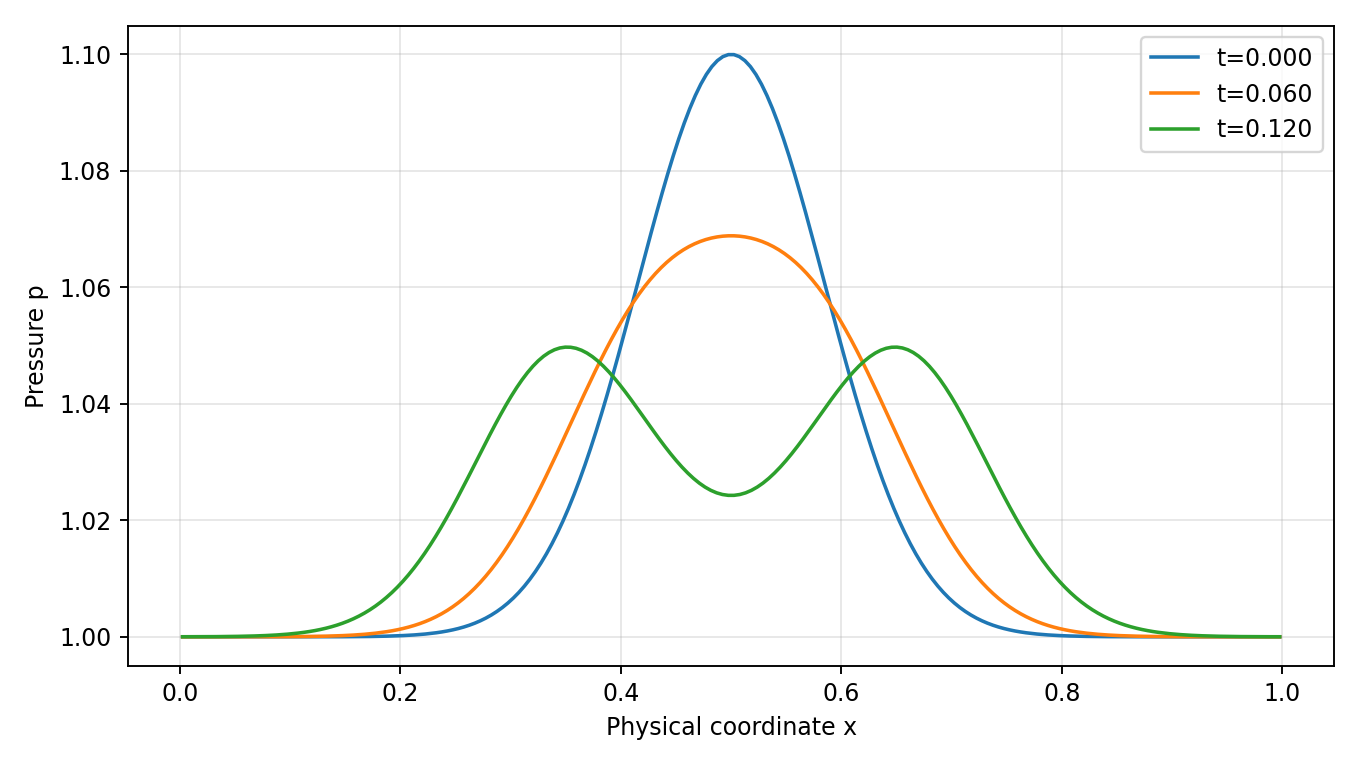

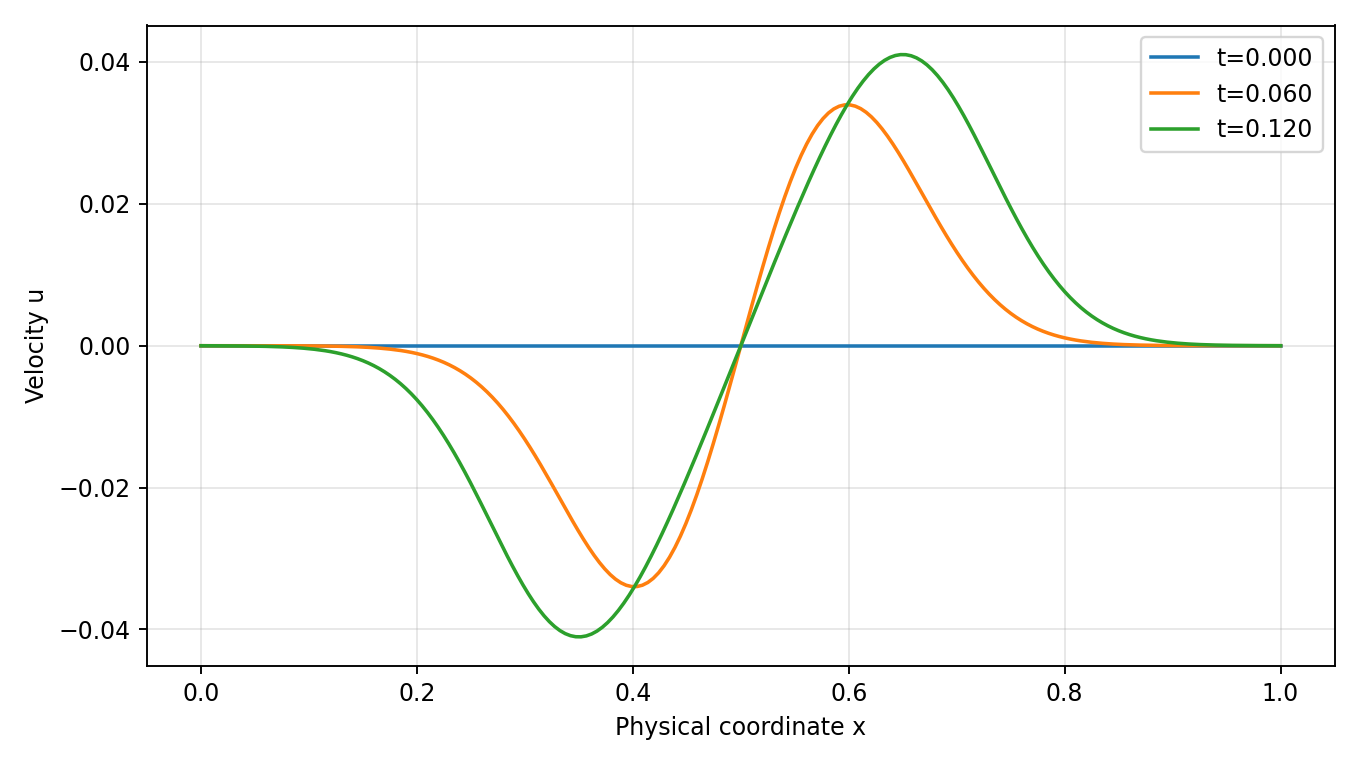

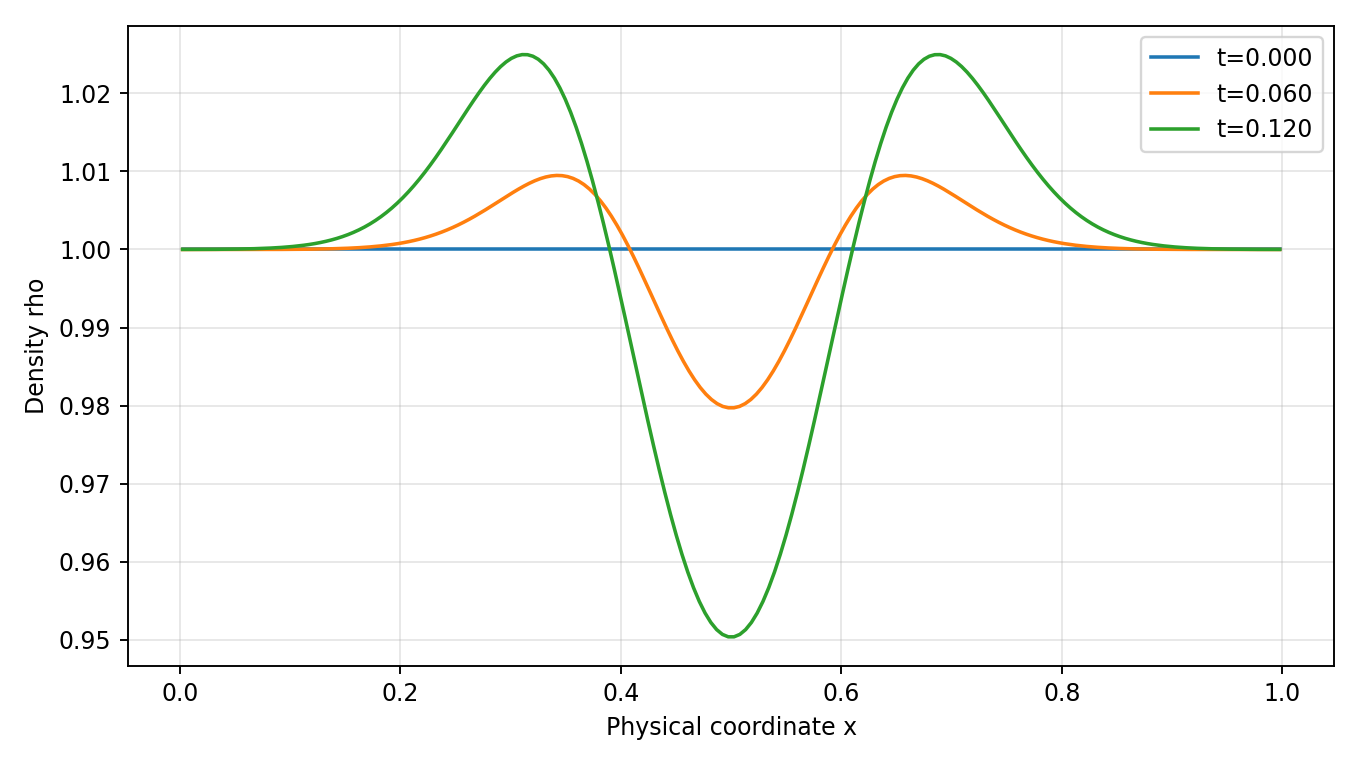

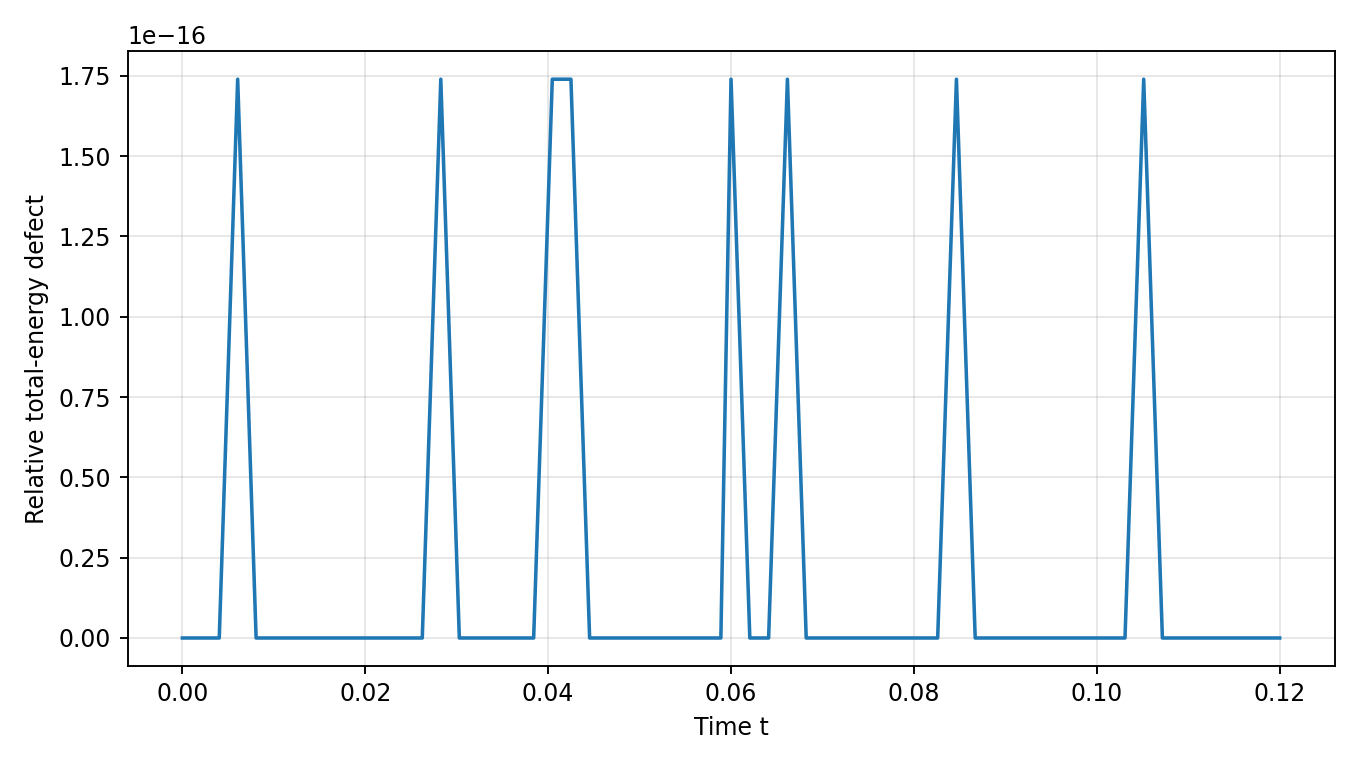

In [ ]:
cfg = Parameters()
snapshots, history = run(cfg)
plot_results(cfg, snapshots, history, directory="gas_dynamics_figures")

from IPython.display import display, Image
for name in ["pressure.png", "velocity.png", "density.png", "energy_error.png"]:
    display(Image(filename=f"gas_dynamics_figures/{name}"))

## Что исследовать далее

1. **Сходимость:** $N=100,200,400$ и сравнение с эталонным численным решением.
2. **Параметр $\alpha$:** сравнить $\alpha=1/2$ с $\alpha=1$ (понадобится изменить формулу замыкания давления и якобиан).
3. **Ударная волна:** задача о распаде разрыва и добавление согласованной искусственной вязкости. В текущем коде искусственной вязкости **нет**, поэтому применять его непосредственно к сильным ударным волнам не следует.
4. **Итерации:** зависимость числа итераций Ньютона от $\tau$ и начального возмущения.